**COMPARACIÓN DE MODELOS PREENTRENADOS PARA CLASIFICACIÓN DE TEXTO**

1. Configurar Entorno

In [ ]:
#instalar las librerías necesarias para el proyecto
!pip install -q transformers datasets scikit-learn pandas matplotlib huggingface_hub

In [ ]:
#importar librerías generales
import time
import re
import pandas as pd
import matplotlib.pyplot as plt
import torch

#librerías de hugging face
from datasets import load_dataset
from transformers import pipeline, AutoConfig
from huggingface_hub import notebook_login

#métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [ ]:
#verificar si hay GPU disponible
if torch.cuda.is_available():
    device = 0
    print("GPU disponible:", torch.cuda.get_device_name(0))
else:
    device = -1
    print("No hay GPU disponible. Se utilizará CPU.")

GPU disponible: Tesla T4


2. Cargar Dataset

In [ ]:
#iniciar sesión en hugging face
#crear un token de lectura desde https://huggingface.co/settings/tokens

notebook_login()

In [ ]:
#cargar el dataset BANKING77
dataset = load_dataset("mteb/banking77")

In [ ]:
#mostrar el tamaño del dataset
print("Ejemplos de entrenamiento:", len(dataset["train"]))
print("Ejemplos de prueba:", len(dataset["test"]))

#mostrar las columnas
print("\nColumnas:")
print(dataset["train"].column_names)

#mostrar algunos ejemplos
df_muestra = pd.DataFrame(dataset["train"][:5])
display(df_muestra)

Ejemplos de entrenamiento: 9993
Ejemplos de prueba: 3076

Columnas:
['text', 'label', 'label_text']


,text,label,label_text
0,I am still waiting on my card?,11,card_arrival
1,What can I do if my card still hasn't arrived ...,11,card_arrival
2,I have been waiting over a week. Is the card s...,11,card_arrival
3,Can I track my card while it is in the process...,11,card_arrival
4,"How do I know if I will get my card, or if it ...",11,card_arrival


In [ ]:
#obtener los textos y las categorías reales del conjunto de prueba
textos = [str(texto) for texto in dataset["test"]["text"]]
etiquetas_reales = dataset["test"]["label_text"]

#comprobar que los datos tengan el formato esperado
print("Total de textos:", len(textos))
print("Total de categorías reales:", len(etiquetas_reales))
print("Tipo de dato de los textos:", type(textos[0]))
print("\nEjemplo de texto:")
print(textos[0])
print("\nCategoría real:")
print(etiquetas_reales[0])

Total de textos: 3076
Total de categorías reales: 3076
Tipo de dato de los textos: <class 'str'>

Ejemplo de texto:
How do I locate my card?

Categoría real:
card_arrival


3. Definir Modelos

In [ ]:
#definir los modelos preentrenados que se van a comparar
modelos = {
    "DistilBERT": "philschmid/DistilBERT-Banking77",
    "BERT": "philschmid/BERT-Banking77",
    "DistilRoBERTa": "mrm8488/distilroberta-finetuned-banking77"
}

#mostrar los modelos seleccionados
for nombre, identificador in modelos.items():
    print(nombre, ":", identificador)

DistilBERT : philschmid/DistilBERT-Banking77
BERT : philschmid/BERT-Banking77
DistilRoBERTa : mrm8488/distilroberta-finetuned-banking77


In [ ]:
#función para normalizar los nombres de las categorías
def normalizar_etiqueta(etiqueta):
    etiqueta = etiqueta.lower().strip()
    etiqueta = etiqueta.replace("-", "_").replace(" ", "_")
    return etiqueta

#crear un diccionario con las categorías reales del dataset
categorias_dataset = {
    normalizar_etiqueta(etiqueta): etiqueta
    for etiqueta in set(etiquetas_reales)
}

print("Número de categorías en el dataset:", len(categorias_dataset))

#revisar las etiquetas que utiliza cada modelo
for nombre, identificador in modelos.items():

    print("\nModelo:", nombre)

    #cargar la configuración del modelo
    config = AutoConfig.from_pretrained(identificador)

    #obtener las etiquetas que reconoce el modelo
    etiquetas_modelo = list(config.id2label.values())

    print("Número de etiquetas:", len(etiquetas_modelo))
    print("Primeras cinco etiquetas:", etiquetas_modelo[:5])

    #comprobar si todas las etiquetas del modelo existen en el dataset
    etiquetas_no_encontradas = [
        etiqueta for etiqueta in etiquetas_modelo
        if normalizar_etiqueta(etiqueta) not in categorias_dataset
    ]

    #comprobar si el modelo tiene todas las categorías esperadas
    etiquetas_normalizadas = {
        normalizar_etiqueta(etiqueta)
        for etiqueta in etiquetas_modelo
    }

    categorias_faltantes = [
        categoria
        for categoria in categorias_dataset
        if categoria not in etiquetas_normalizadas
    ]

    #mostrar el resultado de la revisión
    if etiquetas_no_encontradas:
        print("Etiquetas que no coinciden con el dataset:")
        print(etiquetas_no_encontradas[:10])

    elif categorias_faltantes:
        print("Categorías del dataset que faltan en el modelo:")
        print(categorias_faltantes[:10])

    elif len(etiquetas_modelo) != len(categorias_dataset):
        print("Advertencia: el número de etiquetas es diferente al esperado.")

    else:
        print("Las etiquetas coinciden con las categorías del dataset.")

Número de categorías en el dataset: 77

Modelo: DistilBERT
Número de etiquetas: 77
Primeras cinco etiquetas: ['Refund_not_showing_up', 'activate_my_card', 'age_limit', 'apple_pay_or_google_pay', 'atm_support']
Las etiquetas coinciden con las categorías del dataset.

Modelo: BERT
Número de etiquetas: 77
Primeras cinco etiquetas: ['Refund_not_showing_up', 'activate_my_card', 'age_limit', 'apple_pay_or_google_pay', 'atm_support']
Las etiquetas coinciden con las categorías del dataset.

Modelo: DistilRoBERTa


config.json:   0%|          | 0.00/6.59k [00:00<?, ?B/s]

Número de etiquetas: 77
Primeras cinco etiquetas: ['activate_my_card', 'age_limit', 'apple_pay_or_google_pay', 'atm_support', 'automatic_top_up']
Las etiquetas coinciden con las categorías del dataset.


4. Evaluación

In [ ]:
#función para evaluar un modelo de clasificación de texto
def evaluar_modelo(nombre, identificador):
    print("\nEvaluando modelo:", nombre)

    #cargar la configuración del modelo
    config = AutoConfig.from_pretrained(identificador)

    #crear un diccionario para relacionar las etiquetas del modelo
    mapa_etiquetas = {
        normalizar_etiqueta(etiqueta): etiqueta
        for etiqueta in config.id2label.values()
    }

    #comprobar que el modelo incluya todas las categorías del dataset
    categorias_faltantes = [
        categoria for categoria in categorias_dataset
        if categoria not in mapa_etiquetas
    ]

    if categorias_faltantes:
        raise ValueError(
            f"El modelo {nombre} no tiene todas las categorías esperadas. "
            f"Ejemplos: {categorias_faltantes[:10]}"
        )

    #cargar el clasificador en GPU
    clasificador = pipeline(
        "text-classification",
        model=identificador,
        device=device
    )

    #medir el tiempo de inferencia
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    #clasificar los textos por lotes
    predicciones = clasificador(
        textos,
        batch_size=32,
        truncation=True
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    tiempo_total = time.perf_counter() - inicio

    #convertir las predicciones a las categorías del dataset
    etiquetas_predichas = []

    for prediccion in predicciones:
        etiqueta = normalizar_etiqueta(prediccion["label"])
        etiqueta_final = categorias_dataset[etiqueta]
        etiquetas_predichas.append(etiqueta_final)

    #calcular las métricas de clasificación
    accuracy = accuracy_score(
        etiquetas_reales, etiquetas_predichas
    )

    precision = precision_score(
        etiquetas_reales,
        etiquetas_predichas,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        etiquetas_reales,
        etiquetas_predichas,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        etiquetas_reales,
        etiquetas_predichas,
        average="macro",
        zero_division=0
    )

    #calcular la latencia promedio por texto en milisegundos
    latencia_media = (tiempo_total / len(textos)) * 1000

    #guardar los resultados del modelo
    resultado = {
        "Modelo": nombre,
        "Accuracy": accuracy,
        "Precision macro": precision,
        "Recall macro": recall,
        "F1-score macro": f1,
        "Tiempo total (s)": tiempo_total,
        "Latencia media (ms/texto)": latencia_media
    }

    #mostrar los resultados
    print("\nAccuracy:", round(accuracy, 4))
    print("Precision macro:", round(precision, 4))
    print("Recall macro:", round(recall, 4))
    print("F1-score macro:", round(f1, 4))
    print("Tiempo total (s):", round(tiempo_total, 2))
    print("Latencia media (ms/texto):", round(latencia_media, 2))

    #liberar recursos de memoria
    del clasificador

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return resultado

In [ ]:
#crear una lista para almacenar los resultados
resultados = []

#evaluar cada modelo
for nombre, identificador in modelos.items():
    resultado = evaluar_modelo(nombre, identificador)
    resultados.append(resultado)

print("\nEvaluación finalizada")


Evaluando modelo: DistilBERT


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Accuracy: 0.9223
Precision macro: 0.9258
Recall macro: 0.9223
F1-score macro: 0.9223
Tiempo total (s): 3.68
Latencia media (ms/texto): 1.2

Evaluando modelo: BERT


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Accuracy: 0.9278
Precision macro: 0.9307
Recall macro: 0.9278
F1-score macro: 0.9278
Tiempo total (s): 7.16
Latencia media (ms/texto): 2.33

Evaluando modelo: DistilRoBERTa


...

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]


Accuracy: 0.8963
Precision macro: 0.9064
Recall macro: 0.8963
F1-score macro: 0.8917
Tiempo total (s): 3.75
Latencia media (ms/texto): 1.22

Evaluación finalizada


5. Resultados

In [ ]:
#crear una tabla con los resultados de los tres modelos
df_resultados = pd.DataFrame(resultados)

#ordenar los modelos según su F1-score macro
df_resultados = df_resultados.sort_values(
    by="F1-score macro",
    ascending=False
).reset_index(drop=True)

#mostrar las métricas con cuatro decimales
display(df_resultados.style.format({
    "Accuracy": "{:.4f}",
    "Precision macro": "{:.4f}",
    "Recall macro": "{:.4f}",
    "F1-score macro": "{:.4f}",
    "Tiempo total (s)": "{:.2f}",
    "Latencia media (ms/texto)": "{:.2f}"
}))


,Modelo,Accuracy,Precision macro,Recall macro,F1-score macro,Tiempo total (s),Latencia media (ms/texto)
0,BERT,0.9278,0.9307,0.9278,0.9278,7.16,2.33
1,DistilBERT,0.9223,0.9258,0.9223,0.9223,3.68,1.20
2,DistilRoBERTa,0.8963,0.9064,0.8963,0.8917,3.75,1.22


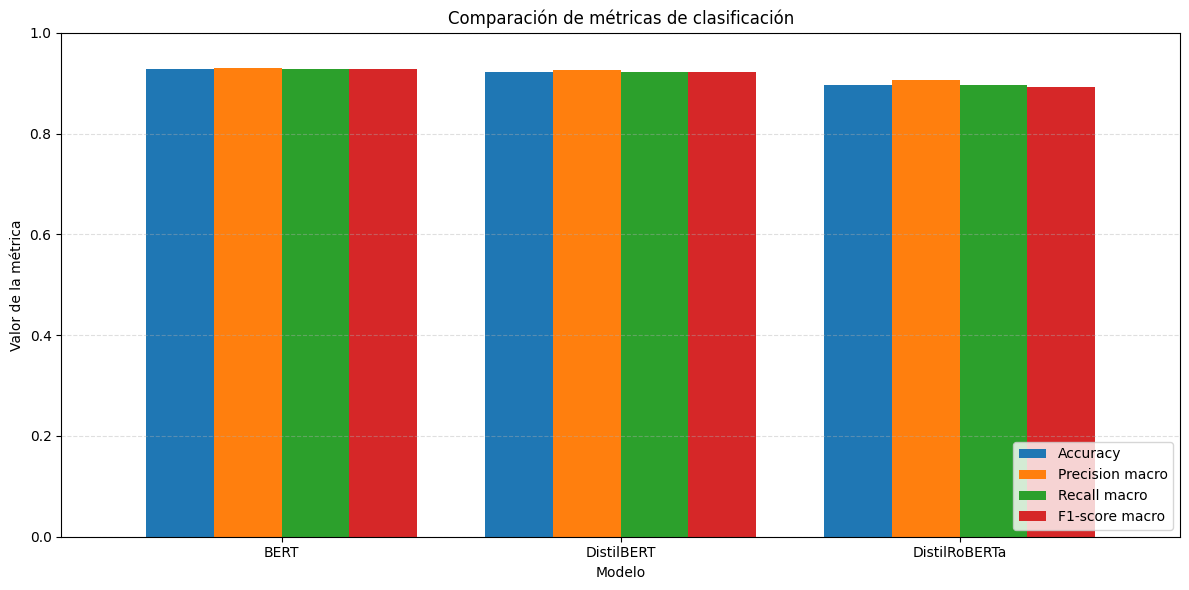

In [ ]:
#comparar las métricas de clasificación de los tres modelos
metricas = [
    "Accuracy",
    "Precision macro",
    "Recall macro",
    "F1-score macro"
]

df_metricas = df_resultados.set_index("Modelo")[metricas]

ax = df_metricas.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("Comparación de métricas de clasificación")
plt.ylabel("Valor de la métrica")
plt.xlabel("Modelo")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

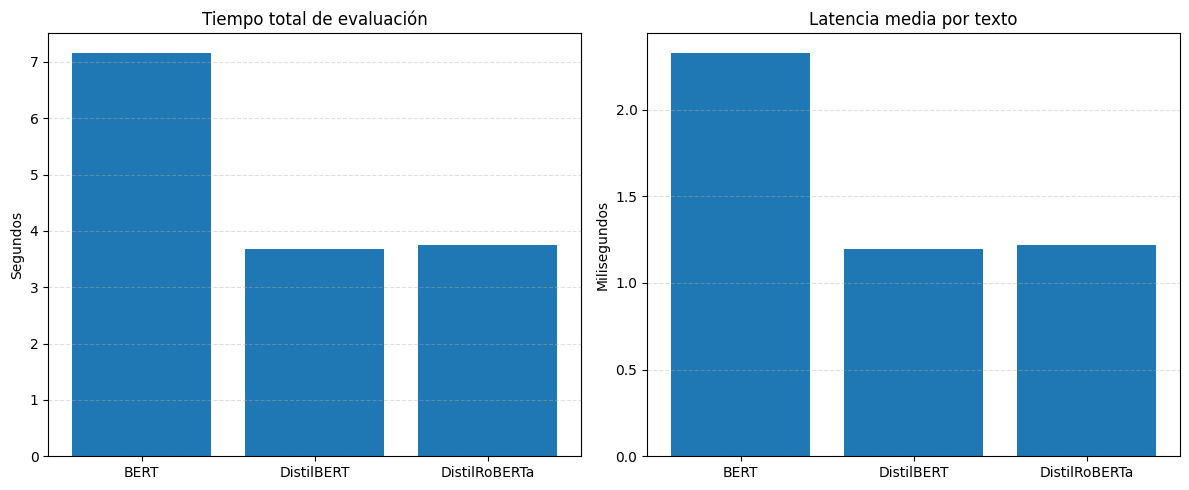

In [ ]:
#comparar los tiempos de ejecución de los modelos
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

#tiempo total de evaluación
ejes[0].bar(
    df_resultados["Modelo"],
    df_resultados["Tiempo total (s)"]
)
ejes[0].set_title("Tiempo total de evaluación")
ejes[0].set_ylabel("Segundos")
ejes[0].grid(axis="y", linestyle="--", alpha=0.4)

#latencia media por texto
ejes[1].bar(
    df_resultados["Modelo"],
    df_resultados["Latencia media (ms/texto)"]
)
ejes[1].set_title("Latencia media por texto")
ejes[1].set_ylabel("Milisegundos")
ejes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
#guardar la tabla comparativa en un archivo CSV
nombre_archivo = "resultados_modelos_banking77.csv"

df_resultados.to_csv(
    nombre_archivo,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo guardado:", nombre_archivo)


Archivo guardado: resultados_modelos_banking77.csv


6. Ejemplos Predicciones

In [ ]:
#seleccionar el modelo con el mejor F1-score macro
mejor_modelo = df_resultados.iloc[0]["Modelo"]
identificador_mejor = modelos[mejor_modelo]

print("Modelo seleccionado:", mejor_modelo)

#cargar el clasificador del modelo seleccionado
clasificador_mejor = pipeline(
    "text-classification",
    model=identificador_mejor,
    device=device
)

#seleccionar algunos ejemplos del conjunto de prueba
cantidad_ejemplos = 10
textos_ejemplo = textos[:cantidad_ejemplos]
reales_ejemplo = etiquetas_reales[:cantidad_ejemplos]

#obtener las predicciones
predicciones_ejemplo = clasificador_mejor(
    textos_ejemplo,
    truncation=True
)

#preparar una tabla para comparar los resultados
tabla_ejemplos = pd.DataFrame({
    "Texto": textos_ejemplo,
    "Categoría real": reales_ejemplo,
    "Categoría predicha": [
        categorias_dataset.get(
            normalizar_etiqueta(p["label"]),
            p["label"]
        )
        for p in predicciones_ejemplo
    ],
    "Confianza": [
        round(p["score"], 4)
        for p in predicciones_ejemplo
    ]
})

tabla_ejemplos["¿Correcta?"] = (
    tabla_ejemplos["Categoría real"]
    == tabla_ejemplos["Categoría predicha"]
)

display(tabla_ejemplos)


Modelo seleccionado: BERT


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,Texto,Categoría real,Categoría predicha,Confianza,¿Correcta?
0,How do I locate my card?,card_arrival,card_arrival,0.4665,True
1,"I still have not received my new card, I order...",card_arrival,card_arrival,0.9775,True
2,I ordered a card but it has not arrived. Help ...,card_arrival,card_arrival,0.9253,True
3,Is there a way to know when my card will arrive?,card_arrival,card_delivery_estimate,0.9448,False
4,My card has not arrived yet.,card_arrival,card_arrival,0.9809,True
5,When will I get my card?,card_arrival,card_delivery_estimate,0.9672,False
6,Do you know if there is a tracking number for ...,card_arrival,card_arrival,0.9808,True
7,i have not received my card,card_arrival,card_arrival,0.9723,True
8,still waiting on that card,card_arrival,card_arrival,0.9639,True
9,Is it normal to have to wait over a week for m...,card_arrival,card_arrival,0.9751,True


7.  Conclusiones Parciales

In [46]:
#identificar el modelo con mejor F1-score macro
mejor_modelo = df_resultados.loc[
    df_resultados["F1-score macro"].idxmax()
]

modelo_mas_rapido = df_resultados.loc[
    df_resultados["Latencia media (ms/texto)"].idxmin()
]

#mostrar las variables seleccionadas
display(pd.DataFrame([
    mejor_modelo,
    modelo_mas_rapido
]).drop_duplicates().reset_index(drop=True))

,Modelo,Accuracy,Precision macro,Recall macro,F1-score macro,Tiempo total (s),Latencia media (ms/texto)
0,BERT,0.927828,0.930669,0.927797,0.927800,7.156377,2.326521
1,DistilBERT,0.922302,0.925798,0.922261,0.922301,3.682280,1.197100
